# PA3: CNN experiments on ImageNet-100

Use this notebook as an experiment log. Start with the supplied baseline, record every setting you change, and preserve the evidence you will use in `report.md`.

In [1]:
# from pathlib import Path

# import matplotlib.pyplot as plt
# import student_code as sc

# # Choose a location with about 9 GB available for the Hugging Face cache.
# CACHE_DIR = Path.home() / ".cache" / "cst463-imagenet100"
# SEED = 0
# sc.set_seed(SEED)

In [2]:
# train_loader, validation_loader = sc.make_imagenet100_loaders(
#   batch_size=64, seed=SEED, cache_dir=CACHE_DIR
# )
# model = sc.CNNClassifier(channels=[32, 64, 128], optimizer_name="adamw")
# print(f"Trainable parameters: {sc.count_trainable_parameters(model):,}")
# history = sc.train_model(model, train_loader, validation_loader, n_epochs=10)

In [3]:
# epochs = range(1, len(history["train_loss"]) + 1)
# fig, axes = plt.subplots(1, 2, figsize=(11, 4))
# axes[0].plot(epochs, history["train_loss"], label="train")
# axes[0].plot(epochs, history["validation_loss"], label="validation")
# axes[0].set(xlabel="epoch", ylabel="cross-entropy loss", title="Loss")
# axes[1].plot(epochs, history["train_accuracy"], label="train")
# axes[1].plot(epochs, history["validation_accuracy"], label="validation")
# axes[1].set(xlabel="epoch", ylabel="accuracy", title="Accuracy")
# for axis in axes:
#   axis.legend()
# plt.show()

In [39]:
import importlib
from pathlib import Path

import torch
import yaml
import student_code as sc

sc = importlib.reload(sc)

config = yaml.safe_load(
    Path("benchmark-config.yaml").read_text(encoding="utf-8")
)
model = sc.CNNClassifier(**config["model"])
optimizer = model.configure_optimizers()
scheduler = model.configure_scheduler(optimizer)

assert config["batch_size"] == 64
assert sc.count_trainable_parameters(model) == 6_763_748
assert optimizer.param_groups[0]["lr"] == 0.003
assert optimizer.param_groups[0]["weight_decay"] == 0.003
assert model.classifier[2].p == 0.2
assert isinstance(scheduler, torch.optim.lr_scheduler.CosineAnnealingLR)
assert scheduler.T_max == 90
assert scheduler.eta_min == 0.00003

print("Final benchmark configuration matches run 20.")

Final benchmark configuration matches run 20.


## Imports and Device Check

In [26]:
import sys
import torch

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("CUDA runtime:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    
print(f"Python executable: {sys.executable}")

Python: C:\Users\lazym\Downloads\CST463\PA3\.venv\Scripts\python.exe
PyTorch: 2.11.0+cu128
CUDA runtime: 12.8
CUDA available: True
GPU: NVIDIA GeForce RTX 5060 Ti
Python executable: C:\Users\lazym\Downloads\CST463\PA3\.venv\Scripts\python.exe


In [38]:
from pathlib import Path

import torch
import matplotlib.pyplot as plt
import student_code as sc
import importlib

sc = importlib.reload(sc)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"PyTorch version: {torch.__version__}")
print(f"Student code loaded from: {sc.__file__}")
print(f"Training device: {DEVICE}")

if DEVICE.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")

PyTorch version: 2.11.0+cu128
Student code loaded from: C:\Users\lazym\Downloads\CST463\PA3\student_code.py
Training device: cuda
GPU: NVIDIA GeForce RTX 5060 Ti


## Experiment Configuration

In [28]:
# Shared settings for data loading and training.
RUN_CONFIG = {
    "seed": 0,
    "batch_size": 64,
    "image_size": sc.IMAGE_SIZE,
    "epochs": 90,          # Initial end-to-end check; increase for experiments.
    "num_workers": 4,     # Simple starting point for a Windows notebook.
}

# Arguments passed directly to CNNClassifier.
MODEL_CONFIG = {
    "channels": [32, 64, 256, 512, 1024],
    "num_classes": sc.NUM_CLASSES,
    "dropout": 0.2,
    "optimizer_name": "adamw",
    "learning_rate": 3e-3,
    "weight_decay": 3e-3,
    "lr_decay_epoch": None,
    "extra_conv": True,
    "cosine_epochs": RUN_CONFIG["epochs"],
    "cosine_min_lr": 3e-5,
}

# Use this location consistently to reuse the downloaded dataset.
CACHE_DIR = Path.home() / ".cache" / "cst463-imagenet100"

sc.set_seed(RUN_CONFIG["seed"])

print("Run configuration:", RUN_CONFIG)
print("Model configuration:", MODEL_CONFIG)
print("Dataset cache:", CACHE_DIR)

Run configuration: {'seed': 0, 'batch_size': 64, 'image_size': 128, 'epochs': 90, 'num_workers': 4}
Model configuration: {'channels': [32, 64, 256, 512, 1024], 'num_classes': 100, 'dropout': 0.2, 'optimizer_name': 'adamw', 'learning_rate': 0.003, 'weight_decay': 0.003, 'lr_decay_epoch': None, 'extra_conv': True, 'cosine_epochs': 90, 'cosine_min_lr': 3e-05}
Dataset cache: C:\Users\lazym\.cache\cst463-imagenet100


## Your experiments

Before each run, state the hypothesis and the one primary change from the baseline. Record the pinned dataset revision, seed, epochs, batch size, parameter count, optimizer, scheduler, augmentation, and elapsed time. Compare 3--5 deliberate configurations rather than searching blindly.

## Model Shape Check

In [29]:
# Reset the seed before initializing the model's random weights.
sc.set_seed(RUN_CONFIG["seed"])

model = sc.CNNClassifier(**MODEL_CONFIG).to(DEVICE)

parameter_count = sc.count_trainable_parameters(model)
print(model)
print(f"\nTrainable parameters: {parameter_count:,}")

# Two synthetic RGB images with the same shape as our future inputs.
sample_images = torch.randn(
    2,
    3,
    RUN_CONFIG["image_size"],
    RUN_CONFIG["image_size"],
    device=DEVICE,
)

# Evaluation mode prevents this check from updating batch-normalization
# statistics. No gradients are needed for a forward-pass check.
model.eval()
with torch.no_grad():
    sample_logits = model(sample_images)

expected_shape = (2, MODEL_CONFIG["num_classes"])
assert sample_logits.shape == expected_shape
assert torch.isfinite(sample_logits).all().item()

print(f"Input shape:  {tuple(sample_images.shape)}")
print(f"Output shape: {tuple(sample_logits.shape)}")
print("Forward-pass check passed.")

# Restore training mode for later use.
model.train()

CNNClassifier(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=T

CNNClassifier(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=T

## Dataset Loaders

In [30]:
sc.set_seed(RUN_CONFIG["seed"])

train_loader, validation_loader = sc.make_imagenet100_loaders(
    batch_size=RUN_CONFIG["batch_size"],
    image_size=RUN_CONFIG["image_size"],
    seed=RUN_CONFIG["seed"],
    num_workers=RUN_CONFIG["num_workers"],
    cache_dir=CACHE_DIR,
)

print(f"Training images:   {len(train_loader.dataset):,}")
print(f"Validation images: {len(validation_loader.dataset):,}")
print(f"Training batches:  {len(train_loader):,}")
print(f"Validation batches: {len(validation_loader):,}")

# Inspect a validation batch without advancing the training shuffle.
images, labels = next(iter(validation_loader))

print(f"\nImage batch shape: {tuple(images.shape)}")
print(f"Image dtype:       {images.dtype}")
print(f"Label batch shape: {tuple(labels.shape)}")
print(f"Label dtype:       {labels.dtype}")

assert images.shape[1:] == (3, RUN_CONFIG["image_size"], RUN_CONFIG["image_size"])
assert images.dtype == torch.float32
assert labels.dtype == torch.int64
assert ((labels >= 0) & (labels < MODEL_CONFIG["num_classes"])).all().item()

print("\nDataset-loader check passed.")

Training images:   126,689
Validation images: 5,000
Training batches:  1,980
Validation batches: 79

Image batch shape: (64, 3, 128, 128)
Image dtype:       torch.float32
Label batch shape: (64,)
Label dtype:       torch.int64

Dataset-loader check passed.


## Save and Restore Experiment Results

In [31]:
import json
from datetime import datetime, timezone
from uuid import uuid4

RESULTS_DIR = Path(sc.__file__).resolve().parent / "results"
RESULTS_DIR.mkdir(exist_ok=True)


def save_experiment(experiment):
    timestamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
    unique_id = uuid4().hex[:8]
    result_path = RESULTS_DIR / f"experiment_{timestamp}_{unique_id}.json"

    # Exclusive creation prevents overwriting an existing result.
    with result_path.open("x", encoding="utf-8") as file:
        json.dump(experiment, file, indent=2, allow_nan=False)

    return result_path


# Restore completed experiments from previous notebook sessions.
experiments = []

for result_path in sorted(RESULTS_DIR.glob("experiment_*.json")):
    with result_path.open("r", encoding="utf-8") as file:
        experiments.append(json.load(file))

print(f"Loaded {len(experiments)} saved experiments.")
print(f"Results folder: {RESULTS_DIR.resolve()}")

Loaded 19 saved experiments.
Results folder: C:\Users\lazym\Downloads\CST463\PA3\results


In [32]:
check_model = sc.CNNClassifier(**MODEL_CONFIG)
check_optimizer = check_model.configure_optimizers()
check_scheduler = check_model.configure_scheduler(check_optimizer)

assert isinstance(
    check_scheduler,
    torch.optim.lr_scheduler.CosineAnnealingLR,
)
assert check_scheduler.T_max == RUN_CONFIG["epochs"]
assert check_scheduler.eta_min == MODEL_CONFIG["cosine_min_lr"]

print("Scheduler:", type(check_scheduler).__name__)
print("Starting learning rate:", check_optimizer.param_groups[0]["lr"])
print("Cosine duration:", check_scheduler.T_max, "epochs")
print("Minimum learning rate:", check_scheduler.eta_min)

del check_model, check_optimizer, check_scheduler

Scheduler: CosineAnnealingLR
Starting learning rate: 0.003
Cosine duration: 90 epochs
Minimum learning rate: 3e-05


## Train and Restore Experiment Results

In [33]:
from copy import deepcopy

# Preserve earlier experiment results when this cell is rerun.
if "experiments" not in globals():
    experiments = []

# Snapshot the settings so later edits won't change this run's record.
run_settings = deepcopy(RUN_CONFIG)
model_settings = deepcopy(MODEL_CONFIG)

# Start each experiment with fresh weights and a fresh shuffle sequence.
sc.set_seed(run_settings["seed"])
train_loader.generator.manual_seed(run_settings["seed"])

model = sc.CNNClassifier(**model_settings).to(DEVICE)
parameter_count = sc.count_trainable_parameters(model)

print(f"Training on: {DEVICE}")
print(f"Epochs: {run_settings['epochs']}")
print(f"Trainable parameters: {parameter_count:,}")
print("Training started; results will print after all epochs finish.")

history = sc.train_model(
    model=model,
    train_loader=train_loader,
    validation_loader=validation_loader,
    n_epochs=run_settings["epochs"],
    device=DEVICE,
)

# Retain the configuration and metrics for later comparisons and plots.
experiment = {
    "name": f"run_{len(experiments) + 1}",
    "run_config": run_settings,
    "model_config": model_settings,
    "dataset_repository": sc.DATASET_REPOSITORY,
    "dataset_revision": sc.DATASET_REVISION,
    "device": str(DEVICE),
    "parameter_count": parameter_count,
    "history": deepcopy(history),
}

# Save to disk before adding the result to our in-memory collection.
result_path = save_experiment(experiment)
experiments.append(experiment)

print(f"Saved experiment: {result_path.resolve()}")

for epoch in range(len(history["train_loss"])):
    print(
        f"Epoch {epoch + 1:02d} | "
        f"train loss: {history['train_loss'][epoch]:.4f} | "
        f"val loss: {history['validation_loss'][epoch]:.4f} | "
        f"train accuracy: {history['train_accuracy'][epoch]:.2%} | "
        f"val accuracy: {history['validation_accuracy'][epoch]:.2%} | "
        f"time: {history['epoch_seconds'][epoch]:.1f}s"
    )

Training on: cuda
Epochs: 90
Trainable parameters: 6,763,748
Training started; results will print after all epochs finish.
Saved experiment: C:\Users\lazym\Downloads\CST463\PA3\results\experiment_20261026T025713_313527Z_078b621b.json
Epoch 01 | train loss: 3.8633 | val loss: 3.1407 | train accuracy: 11.69% | val accuracy: 23.44% | time: 119.6s
Epoch 02 | train loss: 3.0083 | val loss: 2.6560 | train accuracy: 26.84% | val accuracy: 33.02% | time: 115.0s
Epoch 03 | train loss: 2.5195 | val loss: 2.1307 | train accuracy: 37.29% | val accuracy: 44.64% | time: 116.8s
Epoch 04 | train loss: 2.2132 | val loss: 1.8698 | train accuracy: 44.33% | val accuracy: 50.62% | time: 131.8s
Epoch 05 | train loss: 2.0227 | val loss: 1.7041 | train accuracy: 48.67% | val accuracy: 55.02% | time: 126.4s
Epoch 06 | train loss: 1.8848 | val loss: 1.6233 | train accuracy: 51.90% | val accuracy: 56.82% | time: 117.7s
Epoch 07 | train loss: 1.7810 | val loss: 1.5231 | train accuracy: 54.34% | val accuracy: 60.3

## Loss and Accuracy Plots

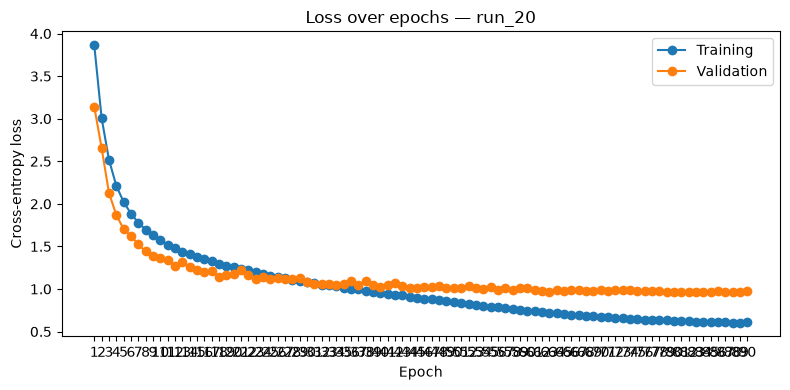

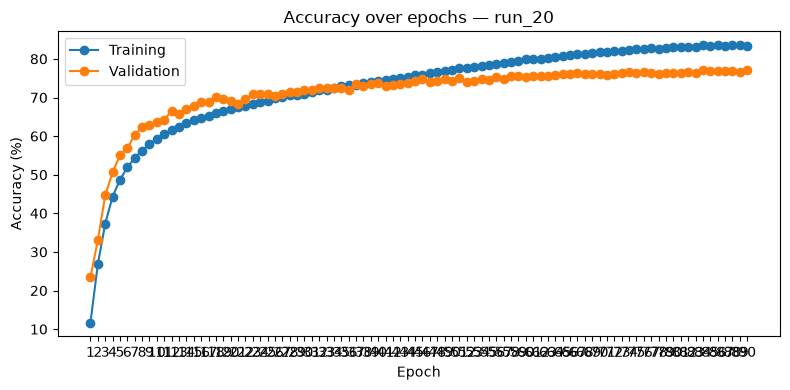

Plots saved in: C:\Users\lazym\Downloads\CST463\PA3\plots


In [34]:
if not globals().get("experiments"):
    print("No completed experiments yet. Finish a training run first.")
else:
    # Use the most recent completed experiment.
    latest_run = experiments[-1]
    metrics = latest_run["history"]
    epochs = range(1, len(metrics["train_loss"]) + 1)
    # Find an unused number, including after a kernel restart.
    plot_dir = Path("plots")
    plot_dir.mkdir(exist_ok=True)

    plot_number = 1
    while (
        (plot_dir / f"experiment_{plot_number:03d}_loss.png").exists()
        or (plot_dir / f"experiment_{plot_number:03d}_accuracy.png").exists()
    ):
        plot_number += 1

    plot_prefix = f"experiment_{plot_number:03d}"

    # Plot 1: loss over epochs.
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(epochs, metrics["train_loss"], marker="o", label="Training")
    ax.plot(epochs, metrics["validation_loss"], marker="o", label="Validation")
    ax.set(
        xlabel="Epoch",
        ylabel="Cross-entropy loss",
        title=f"Loss over epochs — {latest_run['name']}",
        xticks=list(epochs),
    )
    ax.legend()
    fig.tight_layout()
    fig.savefig(
        plot_dir / f"{plot_prefix}_loss.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)

    # Plot 2: accuracy over epochs.
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(
        epochs,
        [100 * value for value in metrics["train_accuracy"]],
        marker="o",
        label="Training",
    )
    ax.plot(
        epochs,
        [100 * value for value in metrics["validation_accuracy"]],
        marker="o",
        label="Validation",
    )
    ax.set(
        xlabel="Epoch",
        ylabel="Accuracy (%)",
        title=f"Accuracy over epochs — {latest_run['name']}",
        xticks=list(epochs),
    )
    ax.legend()
    fig.tight_layout()
    fig.savefig(
        plot_dir / f"{plot_prefix}_accuracy.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)

    print(f"Plots saved in: {plot_dir.resolve()}")

## Compare Experiment Configurations

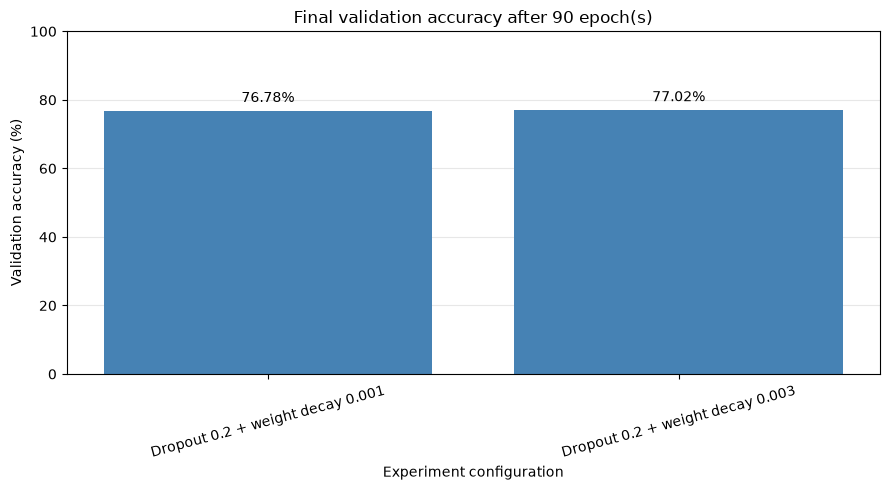

Saved: C:\Users\lazym\Downloads\CST463\PA3\plots\comparison_015.png

Dropout 0.2 + weight decay 0.001 (run_19)
  Model settings: {'channels': [32, 64, 256, 512, 1024], 'num_classes': 100, 'dropout': 0.2, 'optimizer_name': 'adamw', 'learning_rate': 0.003, 'weight_decay': 0.001, 'lr_decay_epoch': None, 'extra_conv': True, 'cosine_epochs': 90, 'cosine_min_lr': 3e-05}
  Trainable parameters: 6,763,748
  Training + validation time: 172.7 minutes

Dropout 0.2 + weight decay 0.003 (run_20)
  Model settings: {'channels': [32, 64, 256, 512, 1024], 'num_classes': 100, 'dropout': 0.2, 'optimizer_name': 'adamw', 'learning_rate': 0.003, 'weight_decay': 0.003, 'lr_decay_epoch': None, 'extra_conv': True, 'cosine_epochs': 90, 'cosine_min_lr': 3e-05}
  Trainable parameters: 6,763,748
  Training + validation time: 173.3 minutes


In [35]:
# Map saved run names to descriptive labels.
# Update this mapping as you complete experiments.
COMPARISON_RUNS = {
    "run_19": "Dropout 0.2 + weight decay 0.001",
    "run_20": "Dropout 0.2 + weight decay 0.003",
}

runs_by_name = {
    experiment["name"]: experiment
    for experiment in experiments
}

missing = [
    name for name in COMPARISON_RUNS
    if name not in runs_by_name
]

if missing:
    print("These runs have not been completed or loaded:", missing)
elif len(COMPARISON_RUNS) < 2:
    print("Select at least two completed experiments for comparison.")
else:
    selected_runs = [
        runs_by_name[name] for name in COMPARISON_RUNS
    ]

    # Check that runs share the basic comparison conditions.
    def comparison_conditions(run):
        settings = run["run_config"]
        return (
            run["dataset_repository"],
            run["dataset_revision"],
            settings["seed"],
            settings["batch_size"],
            settings["image_size"],
            settings["epochs"],
        )

    reference_conditions = comparison_conditions(selected_runs[0])

    if any(
        comparison_conditions(run) != reference_conditions
        for run in selected_runs
    ):
        raise ValueError(
            "Choose runs with the same dataset, seed, batch size, "
            "image size, and epoch budget."
        )

    for run in selected_runs:
        if (
            len(run["history"]["validation_accuracy"])
            != run["run_config"]["epochs"]
        ):
            raise ValueError(f"{run['name']} has incomplete epoch metrics.")

    labels = list(COMPARISON_RUNS.values())
    accuracies = [
        100 * run["history"]["validation_accuracy"][-1]
        for run in selected_runs
    ]
    epoch_budget = selected_runs[0]["run_config"]["epochs"]

    fig, ax = plt.subplots(figsize=(9, 5))
    bars = ax.bar(labels, accuracies, color="steelblue")
    ax.bar_label(bars, fmt="%.2f%%", padding=4)
    ax.set(
        xlabel="Experiment configuration",
        ylabel="Validation accuracy (%)",
        title=f"Final validation accuracy after {epoch_budget} epoch(s)",
        ylim=(0, 100),
    )
    ax.tick_params(axis="x", labelrotation=15)
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.3)
    fig.tight_layout()

    plot_dir = Path("plots")
    plot_dir.mkdir(exist_ok=True)

    plot_number = 1
    plot_path = plot_dir / f"comparison_{plot_number:03d}.png"
    while plot_path.exists():
        plot_number += 1
        plot_path = plot_dir / f"comparison_{plot_number:03d}.png"

    fig.savefig(plot_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"Saved: {plot_path.resolve()}")

    # Show the exact settings and training cost behind each bar.
    for label, run in zip(labels, selected_runs):
        minutes = sum(run["history"]["epoch_seconds"]) / 60
        print(f"\n{label} ({run['name']})")
        print(f"  Model settings: {run['model_config']}")
        print(f"  Trainable parameters: {run['parameter_count']:,}")
        print(f"  Training + validation time: {minutes:.1f} minutes")

In [37]:
last_five_accuracy = sum(history["validation_accuracy"][-5:]) / 5
print(f"Final-five mean validation accuracy: {last_five_accuracy:.3%}")

Final-five mean validation accuracy: 76.828%
